In [42]:
!pip -q install --index-url https://download.pytorch.org/whl/cu121 torch torchvision torchaudio timm safetensors

In [43]:
import sys
from pathlib import Path

import torch
import torchvision
import timm

print('PyTorch:', torch.__version__, '/ torchvision:', torchvision.__version__, '/ timm:', timm.__version__)
print('PyTorch CUDA:', torch.version.cuda)
if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU를 사용할 수 없습니다. 커널, NVIDIA 드라이버, CUDA용 PyTorch 설치를 확인하세요.")

print('GPU:', torch.cuda.get_device_name(0))
torch.zeros(1, device='cuda').sum().item()
print('커널과 GPU 확인 완료')

torch.manual_seed(42)
device = 'cuda'


PyTorch: 2.14.1+cu130 / torchvision: 0.29.1+cu130 / timm: 1.0.31
PyTorch CUDA: 13.0
GPU: Tesla T4
커널과 GPU 확인 완료


In [44]:
# 구글드라이브 마운트
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [45]:
!7z x -y -o/content/ "/content/drive/MyDrive/constructing_tiny_vit.zip"


7-Zip 23.01 (x64) : Copyright (c) 1999-2023 Igor Pavlov : 2023-06-20
 64-bit locale=en_US.UTF-8 Threads:2 OPEN_MAX:1048576

Scanning the drive for archives:
  0M Scan /content/drive/MyDrive/                                 1 file, 81222691 bytes (78 MiB)

Extracting archive: /content/drive/MyDrive/ai-level-3-11-7.zip
 26% 4096 Open              --
Path = /content/drive/MyDrive/ai-level-3-11-7.zip
Type = zip
Physical Size = 81222691

  0%     12% 1873          24% 3544          36% 5436          48% 7364 - train/train_003952.png                                   60% 9221 - train/train_005809.png                                   71% 10942           81% 12492 - train/train_009080.

In [46]:
import os
print("현재 디렉토리:", os.getcwd())
print("현재 디렉토리 파일 목록:", os.listdir('.'))


현재 디렉토리: /content
현재 디렉토리 파일 목록: ['.config', 'train', 'outputs', 'train.csv', 'drive', 'test.csv', 'tiny_vit_5m_224.dist_in22k_ft_in1k.safetensors', 'classes.json', 'test', 'sample_submission.csv', 'sample_data']


In [47]:
import csv
import json
import time

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from sklearn.metrics import accuracy_score
from torchvision.transforms import InterpolationMode

import pandas as pd
import json
from pathlib import Path
from sklearn.model_selection import train_test_split

output_dir = Path('outputs')
output_dir.mkdir(exist_ok=True)
checkpoint = output_dir / 'model.pt'
history_path = output_dir / 'model_history.csv'
submission_path = Path('submission.csv')

# 클래스 정보 로드
with open('classes.json', 'r', encoding='utf-8') as file:
    class_names = json.load(file)
num_classes = len(class_names)
print('클래스 개수:', num_classes)

# train.csv 데이터프레임 로드
df_train_all = pd.read_csv('train.csv')

# 학습용/검증용 데이터 분할 (8:2)
train_df, val_df = train_test_split(df_train_all, test_size=0.2, random_state=42, stratify=df_train_all['label'] if 'label' in df_train_all.columns else None)

# 테스트 ID 목록
df_test = pd.read_csv('test.csv')
test_ids = df_test['id'].tolist()

print('학습 데이터 수:', len(train_df), '검증 데이터 수:', len(val_df), '테스트 데이터 수:', len(test_ids))


클래스 개수: 20
학습 데이터 수: 9600 검증 데이터 수: 2400 테스트 데이터 수: 3408


In [48]:
mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)
fill = (124, 116, 104)

eval_transform = T.Compose([
    T.ToTensor(),
    T.Normalize(mean, std),
])

train_transform = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    # 기하학적 변환
    T.RandomAffine(
        degrees=18, # -18도에서 18도 사이의 임의의 각도로 이미지 회전
        translate=(0.08, 0.08), # 이미지의 8%만 상하좌우 이동
        scale=(0.90, 1.10), # 원래 크기의 90%에서 110% 사이의 배율로 무작위 크기 조절
        shear=8, # -8도 ~ 8도 범위 내에서 이미지 기울이기
        interpolation=InterpolationMode.BILINEAR,
        fill=fill,
    ),
    # 색상 변환
    T.ColorJitter(brightness=0.12, contrast=0.12, saturation=0.08),
    T.ToTensor(), # 텐서 변환
    T.RandomErasing(p=0.15, scale=(0.01, 0.06), ratio=(0.5, 2.0), value=mean),
    T.Normalize(mean, std), # 정규화
])


In [49]:
# train/validation DataFrame으로부터 이미지를 실시간 로드하는 커스텀 데이터셋
class FashionDataset(Dataset):
    def __init__(self, df, image_dir, transform):
        self.df = df.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        label = int(row['answer'])
        image_path = self.image_dir / row['id']
        with Image.open(image_path) as img:
            img = self.transform(img.convert('RGB'))
        return img, label

class FashionTestDataset(Dataset):
    def __init__(self, image_dir, ids, transform):
        self.image_dir = Path(image_dir)
        self.ids = ids
        self.transform = transform

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, index):
        sample_id = self.ids[index]
        with Image.open(self.image_dir / sample_id) as image:
            image = self.transform(image.convert('RGB'))
        return image, sample_id

print('테스트 이미지 개수:', len(test_ids))


테스트 이미지 개수: 3408


## TinyViT

**TinyViT 논문**: https://arxiv.org/abs/2207.10666

**Github**: https://github.com/wkcn/TinyViT

In [50]:
model_name = "tiny_vit_5m_224.dist_in22k_ft_in1k"
model = timm.create_model(model_name, pretrained=True)
model.eval()

print(f"성공적으로 모델을 불러왔습니다: {model_name}")

성공적으로 모델을 불러왔습니다: tiny_vit_5m_224.dist_in22k_ft_in1k


In [51]:
class ConvNorm(nn.Sequential):
    """Conv2d와 BatchNorm2d로 구성한 기본 블록."""
    def __init__(self, in_channels, out_channels, kernel_size=1,
                 stride=1, padding=0, groups=1, bn_weight=1.0):
        super().__init__()
        self.conv = nn.Conv2d(
            in_channels, out_channels, kernel_size,
            stride=stride, padding=padding, groups=groups, bias=False,
        )
        self.bn = nn.BatchNorm2d(out_channels)
        nn.init.constant_(self.bn.weight, bn_weight)
        nn.init.zeros_(self.bn.bias)


class PatchEmbed(nn.Module):
    """원본 입력을 특징 맵으로 변환: [B, 3, 80, 60] → [B, 64, 20, 15]."""
    def __init__(self, dim=64):
        super().__init__()
        self.conv1 = ConvNorm(3, dim // 2, 3, stride=2, padding=1)
        self.act = nn.GELU()
        self.conv2 = ConvNorm(dim // 2, dim, 3, stride=2, padding=1)

    def forward(self, x):
        x = self.conv1(x)
        x = self.act(x)
        return self.conv2(x)

class MBConv(nn.Module):
    """Stage 0: 채널 확장 → depthwise convolution → 채널 축소."""
    def __init__(self, dim, expand_ratio=4):
        super().__init__()
        hidden_dim = dim * expand_ratio
        self.conv1 = ConvNorm(dim, hidden_dim)
        self.act1 = nn.GELU()
        self.conv2 = ConvNorm(hidden_dim, hidden_dim, 3,
                              padding=1, groups=hidden_dim)
        self.act2 = nn.GELU()
        self.conv3 = ConvNorm(hidden_dim, dim, bn_weight=0.0)
        self.act3 = nn.GELU()

    def forward(self, x):
        shortcut = x
        x = self.act1(self.conv1(x))
        x = self.act2(self.conv2(x))
        x = self.conv3(x)
        return self.act3(x + shortcut)


class ConvStage(nn.Module):
    def __init__(self, dim, depth):
        super().__init__()
        self.blocks = nn.Sequential(*[MBConv(dim) for _ in range(depth)])

    def forward(self, x):
        return self.blocks(x)


class PatchMerging(nn.Module):
    """해상도를 절반으로 줄이고 다음 stage의 채널 수로 변환."""
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.conv1 = ConvNorm(in_dim, out_dim)
        self.act1 = nn.GELU()
        self.conv2 = ConvNorm(out_dim, out_dim, 3, stride=2,
                              padding=1, groups=out_dim)
        self.act2 = nn.GELU()
        self.conv3 = ConvNorm(out_dim, out_dim)

    def forward(self, x):
        x = self.act1(self.conv1(x))
        x = self.act2(self.conv2(x))
        return self.conv3(x)

class NormMLP(nn.Module):
    def __init__(self, dim, mlp_ratio=4):
        super().__init__()
        self.norm = nn.LayerNorm(dim)
        self.fc1 = nn.Linear(dim, dim * mlp_ratio)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(dim * mlp_ratio, dim)

    def forward(self, x):
        x = self.norm(x)
        x = self.fc1(x)
        x = self.act(x)
        return self.fc2(x)


class WindowAttention(nn.Module):
    """작은 window 안에서 수행하는 multi-head self-attention."""
    def __init__(self, dim, num_heads, window_size):
        super().__init__()
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.norm = nn.LayerNorm(dim)
        self.qkv = nn.Linear(dim, dim * 3)
        self.proj = nn.Linear(dim, dim)

        # window 내 두 위치 사이의 상대 거리에 따른 학습 가능한 bias
        coords = torch.stack(torch.meshgrid(
            torch.arange(window_size), torch.arange(window_size), indexing="ij"
        )).flatten(1)
        offsets = (coords[:, :, None] - coords[:, None, :]).abs()
        bias_indices = offsets[0] * window_size + offsets[1]
        self.register_buffer("attention_bias_idxs", bias_indices, persistent=False)
        self.attention_biases = nn.Parameter(
            torch.zeros(num_heads, window_size * window_size)
        )

    def forward(self, x):
        batch_size, num_tokens, dim = x.shape
        x = self.norm(x)

        # 체크포인트의 QKV 배치 순서: 각 head 안에 Q, K, V가 들어 있습니다.
        qkv = self.qkv(x).reshape(
            batch_size, num_tokens, self.num_heads, 3 * self.head_dim
        )
        qkv = qkv.transpose(1, 2)
        q, k, v = qkv.chunk(3, dim=-1)

        attention = (q * self.scale) @ k.transpose(-2, -1)
        bias = self.attention_biases[:, self.attention_bias_idxs]
        attention = (attention + bias.unsqueeze(0)).softmax(dim=-1)
        x = attention @ v
        x = x.transpose(1, 2).reshape(batch_size, num_tokens, dim)
        return self.proj(x)

In [52]:
class TinyViTBlock(nn.Module):
    """윈도 어텐션 → 지역 합성곱 → 다층 퍼셉트론."""
    def __init__(self, dim, num_heads, window_size):
        super().__init__()
        self.window_size = window_size
        self.attn = WindowAttention(dim, num_heads, window_size)
        self.local_conv = ConvNorm(dim, dim, 3, padding=1, groups=dim)
        self.mlp = NormMLP(dim)

    def forward(self, x):
        # 이 블록 안에서는 [B, H, W, C] 순서로 처리합니다.
        batch_size, height, width, channels = x.shape
        shortcut = x
        window = self.window_size

        # 해상도가 window 크기의 배수가 아닐 때 오른쪽·아래쪽에 padding
        pad_h = (window - height % window) % window
        pad_w = (window - width % window) % window
        x = F.pad(x, (0, 0, 0, pad_w, 0, pad_h))
        padded_h, padded_w = height + pad_h, width + pad_w
        num_h, num_w = padded_h // window, padded_w // window

        # 이미지 → 여러 window
        x = x.reshape(batch_size, num_h, window, num_w, window, channels)
        x = x.transpose(2, 3).reshape(-1, window * window, channels)
        x = self.attn(x)

        # 여러 window → 이미지
        x = x.reshape(batch_size, num_h, num_w, window, window, channels)
        x = x.transpose(2, 3).reshape(batch_size, padded_h, padded_w, channels)
        x = x[:, :height, :width, :].contiguous()
        x = shortcut + x

        x = x.permute(0, 3, 1, 2)
        x = self.local_conv(x)
        x = x.flatten(2).transpose(1, 2)
        x = x + self.mlp(x)
        return x.reshape(batch_size, height, width, channels)


class TinyViTStage(nn.Module):
    def __init__(self, in_dim, out_dim, depth, num_heads, window_size):
        super().__init__()
        self.downsample = PatchMerging(in_dim, out_dim)
        self.blocks = nn.Sequential(*[
            TinyViTBlock(out_dim, num_heads, window_size) for _ in range(depth)
        ])

    def forward(self, x):
        x = self.downsample(x)
        x = x.permute(0, 2, 3, 1)
        x = self.blocks(x)
        return x.permute(0, 3, 1, 2)

In [53]:
from safetensors.torch import load_file

class ClassifierHead(nn.Module):
    def __init__(self, dim, num_classes):
        super().__init__()
        self.norm = nn.LayerNorm(dim, eps=1e-5)
        self.fc = nn.Linear(dim, num_classes)

    def forward(self, x):
        x = x.mean(dim=(2, 3))
        x = self.norm(x)
        return self.fc(x)


def load_pretrained_weights(model):
    """제공된 로컬 가중치를 읽고 상대 위치 bias만 입력 크기에 맞게 보간합니다."""
    path = Path('tiny_vit_5m_224.dist_in22k_ft_in1k.safetensors')
    if not path.is_file():
        raise FileNotFoundError(
            f'사전학습 가중치 파일을 찾을 수 없습니다: {path.resolve()}\n'
            '제공된 가중치 파일을 노트북과 같은 폴더에 두고, 작업 폴더를 해당 폴더로 맞추세요.'
        )
    weights = load_file(str(path))
    target = model.state_dict()
    for name, value in weights.items():
        if name.endswith('attention_biases') and value.shape != target[name].shape:
            num_heads, length = value.shape
            old_window = int(length ** 0.5)
            new_window = int(target[name].shape[1] ** 0.5)
            weights[name] = F.interpolate(
                value.float().reshape(1, num_heads, old_window, old_window),
                size=(new_window, new_window),
                mode='bicubic', antialias=True,
            ).reshape(num_heads, new_window * new_window)
    model.load_state_dict(weights, strict=True)

In [54]:
import os
import shutil
from pathlib import Path

# 구글 드라이브와 로컬 경로에서 가중치 파일 탐색
target_filename = 'tiny_vit_5m_224.dist_in22k_ft_in1k.safetensors'
found_path = None

for root, dirs, files in os.walk('.'):
    if target_filename in files:
        found_path = Path(root) / target_filename
        break

if not found_path and os.path.exists('/content/drive'):
    print("구글 드라이브에서 가중치 파일 검색 중...")
    for root, dirs, files in os.walk('/content/drive'):
        if target_filename in files:
            found_path = Path(root) / target_filename
            break

if found_path:
    print(f"가중치 파일을 찾았습니다: {found_path}")
    dest_path = Path('/content') / target_filename
    if found_path.resolve() != dest_path.resolve():
        shutil.copy(found_path, dest_path)
        print(f"가중치 파일을 {dest_path} 경로로 복사 완료했습니다.")
else:
    print(f"시스템 내에 {target_filename} 파일이 존재하지 않습니다. 외부 다운로드를 시도합니다.")
    !wget -q https://huggingface.co/timm/tiny_vit_5m_224.dist_in22k_ft_in1k/resolve/main/model.safetensors -O /content/tiny_vit_5m_224.dist_in22k_ft_in1k.safetensors
    print("Hugging Face 저장소로부터 가중치 다운로드 완료.")


가중치 파일을 찾았습니다: tiny_vit_5m_224.dist_in22k_ft_in1k.safetensors


In [55]:
class FashionModel(nn.Module):
    """원본 크기의 이미지에서 전체 파라미터를 미세조정하는 TinyViT 5M입니다."""
    def __init__(self):
        super().__init__()
        self.patch_embed = PatchEmbed(dim=64)
        self.stages = nn.Sequential(
            ConvStage(dim=64, depth=2),
            TinyViTStage(64, 128, depth=2, num_heads=4, window_size=3),
            TinyViTStage(128, 160, depth=6, num_heads=5, window_size=5),
            TinyViTStage(160, 320, depth=2, num_heads=10, window_size=3),
        )
        self.head = ClassifierHead(320, num_classes=1000)
        load_pretrained_weights(self)
        self.head.fc = nn.Linear(320, num_classes)

    def forward(self, x):
        x = self.patch_embed(x)
        x = self.stages[0](x)
        x = self.stages[1](x)
        x = self.stages[2](x)
        x = self.stages[3](x)
        x = x.mean(dim=(2, 3))
        x = self.head.norm(x)
        return self.head.fc(x)

In [56]:
batch_size = 64
learning_rate = 0.0001
epochs = 25

train_dataset = FashionDataset(train_df, 'train', train_transform)
val_dataset = FashionDataset(val_df, 'train', eval_transform)
test_dataset = FashionTestDataset('test', test_ids, eval_transform)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)


In [57]:
def train_one_epoch(model, loader, optimizer, loss_fn):
    model.train()
    total_loss = 0
    sample_count = 0
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(labels)
        sample_count += len(labels)
    return total_loss / sample_count


def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss = 0
    predictions, targets = [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            logits = model(images)
            total_loss += loss_fn(logits, labels).item() * len(labels)
            predictions.extend(logits.argmax(1).cpu().tolist())
            targets.extend(labels.cpu().tolist())
    accuracy = accuracy_score(targets, predictions)
    return total_loss / len(targets), accuracy

In [58]:
torch.manual_seed(42)
model = FashionModel().to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
loss_fn = nn.CrossEntropyLoss()
best_accuracy = -1
history = []
started = time.perf_counter()

for epoch in range(epochs):
    train_loss = train_one_epoch(model, train_loader, optimizer, loss_fn)
    val_loss, val_accuracy = evaluate(model, val_loader, loss_fn)
    history.append({
        'epoch': epoch + 1,
        'train_loss': train_loss,
        'val_loss': val_loss,
        'val_accuracy': val_accuracy,
    })
    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        torch.save(model.state_dict(), checkpoint)
    print(f'{epoch + 1:2d}/{epochs}  학습 Loss: {train_loss:.4f}  '
          f'검증 Loss: {val_loss:.4f}  검증 Accuracy: {val_accuracy:.4f}')
    scheduler.step()

with history_path.open('w', encoding='utf-8', newline='') as file:
    writer = csv.DictWriter(file, fieldnames=['epoch', 'train_loss', 'val_loss', 'val_accuracy'])
    writer.writeheader()
    writer.writerows(history)
print(f'최고 검증 Accuracy: {best_accuracy:.4f} / 학습 시간: {time.perf_counter() - started:.1f}초')
print('체크포인트:', checkpoint)

 1/25  학습 Loss: 2.4458  검증 Loss: 1.7213  검증 Accuracy: 0.5308
 2/25  학습 Loss: 1.3257  검증 Loss: 0.9659  검증 Accuracy: 0.7142
 3/25  학습 Loss: 0.8247  검증 Loss: 0.6665  검증 Accuracy: 0.7904
 4/25  학습 Loss: 0.6034  검증 Loss: 0.5467  검증 Accuracy: 0.8250
 5/25  학습 Loss: 0.4868  검증 Loss: 0.4507  검증 Accuracy: 0.8554
 6/25  학습 Loss: 0.4017  검증 Loss: 0.4278  검증 Accuracy: 0.8571
 7/25  학습 Loss: 0.3450  검증 Loss: 0.3813  검증 Accuracy: 0.8729
 8/25  학습 Loss: 0.3048  검증 Loss: 0.3342  검증 Accuracy: 0.8908
 9/25  학습 Loss: 0.2705  검증 Loss: 0.3087  검증 Accuracy: 0.8988
10/25  학습 Loss: 0.2535  검증 Loss: 0.2976  검증 Accuracy: 0.9017
11/25  학습 Loss: 0.2311  검증 Loss: 0.2959  검증 Accuracy: 0.9054
12/25  학습 Loss: 0.2158  검증 Loss: 0.3058  검증 Accuracy: 0.8992
13/25  학습 Loss: 0.2054  검증 Loss: 0.2845  검증 Accuracy: 0.9054
14/25  학습 Loss: 0.1945  검증 Loss: 0.2714  검증 Accuracy: 0.9117
15/25  학습 Loss: 0.1799  검증 Loss: 0.2530  검증 Accuracy: 0.9137
16/25  학습 Loss: 0.1627  검증 Loss: 0.2784  검증 Accuracy: 0.9100
17/25  학습 Loss: 0.1625  

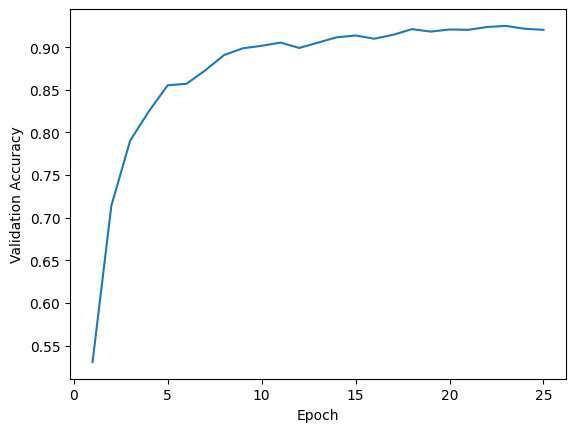

In [61]:
plt.plot([row['epoch'] for row in history], [row['val_accuracy'] for row in history])
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.show()

In [62]:
model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
model.eval()
predicted_ids, predictions = [], []
with torch.no_grad():
    for images, ids in test_loader:
        logits = model(images.to(device))
        predictions.extend(logits.argmax(dim=1).cpu().tolist())
        predicted_ids.extend(ids)

with submission_path.open('w', encoding='utf-8', newline='') as file:
    writer = csv.writer(file)
    writer.writerow(['id', 'answer'])
    writer.writerows(zip(predicted_ids, predictions))
print(f'제출 파일: {submission_path} / {len(predictions)}개 예측')

제출 파일: submission.csv / 3408개 예측
